# Question 2: analysis of the saved Colab results
**Student ID:** 23k-0078

The GPU training notebook is `Assignment_Beta_Question_no_2_23k-0078.ipynb`. This notebook trains nothing. It reads the files that run saved in `../assignment_beta_q2` and works out the extra figures used in the report: corrected percentages, significance tests, a hand-labelled review of the no-call set, and the failures of the best rank.

In [1]:
import json, math, re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

WORK = Path("../assignment_beta_q2")
NAMES = ["Baseline", "LoRA_r8", "QLoRA_r8", "DoRA_r8", "AdaLoRA_r4", "AdaLoRA_r8", "AdaLoRA_r16", "AdaLoRA_r32"]
preds = {n: json.loads((WORK / f"{n}_predictions.json").read_text(encoding="utf-8")) for n in NAMES}
stats = {n: json.loads((WORK / f"{n}.json").read_text()) for n in NAMES}
split = json.loads((WORK / "data_split.json").read_text(encoding="utf-8"))
merge = json.loads((WORK / "merge_check.json").read_text())

def first_json(text):
    decoder, i = json.JSONDecoder(), text.find("{")
    while i >= 0:
        try:
            obj, _ = decoder.raw_decode(text, i)
            if isinstance(obj, dict):
                return obj
        except json.JSONDecodeError:
            pass
        i = text.find("{", i + 1)
    return None

def tool_correct(row):
    obj = first_json(row["output"])
    return bool(obj) and obj.get("name") == json.loads(row["gold"])["name"]

tool = {n: [tool_correct(r) for r in preds[n]["test"]] for n in NAMES}
for n in NAMES:
    assert abs(sum(tool[n]) / 200 - stats[n]["tool_accuracy"]) < 1e-9
print("Tool accuracy recomputed from raw outputs matches the Colab summary for all 8 runs.")

Tool accuracy recomputed from raw outputs matches the Colab summary for all 8 runs.


## Corrected trainable percentage
The Colab table divides by `total_parameters`, which for the 4-bit model counts packed storage and so reads 890,795,520 instead of about 1.54 billion. QLoRA has the same base model and the same adapter size as LoRA, so its true share is the same.

In [2]:
base_total = stats["Baseline"]["total_parameters"]
adapter = stats["QLoRA_r8"]["trainable_parameters"]
qlora_percent = 100 * adapter / (base_total + adapter)
print(f"QLoRA: raw {stats['QLoRA_r8']['trainable_percent']:.4f}%, corrected {qlora_percent:.4f}%")
print(f"AdaLoRA r=8 after allocation: {stats['AdaLoRA_r8']['effective_trainable']:,} parameters")
print(f"Adam state for the r=8 adapter: 2 x {adapter:,} x 4 bytes = {2 * adapter * 4 / 1e6:.1f} MB")

QLoRA: raw 0.2446%, corrected 0.1410%
AdaLoRA r=8 after allocation: 1,936,768 parameters
Adam state for the r=8 adapter: 2 x 2,179,072 x 4 bytes = 17.4 MB


## Why tuned models stop calling tools
The parser treated any first reply without a `<functioncall>` tag as a no-call example. Many of those replies only promise an action, because Glaive puts the real call in a later turn.

In [3]:
OPENER = re.compile(r"\s*(sure|of course|certainly|absolutely)", re.I)
APOLOGY = re.compile(r"sorry|unable|can't|cannot|don't have|not able", re.I)
ASK = re.compile(r"\?|please (provide|tell|share|give|specify|let me know)|could you|can you|what|which|how (long|many|much)|need (the|your|some|more)", re.I)
train = split["train"]
no_call_train = [e for e in train if e["kind"] == "no_call"]
stalls = [e for e in no_call_train if not ASK.search(e["target"]) and not APOLOGY.search(e["target"])]
inline = [e for e in no_call_train if "AI to=" in e["target"]]
greeting = lambda text: text.lower().startswith(("hi", "hello", "hey"))
print(f"Training: {len(train)} examples, {len(no_call_train)} no-call")
print(f"No-call targets with a promise and no question or apology: {len(stalls)} ({100 * len(stalls) / len(no_call_train):.0f}%)")
print(f"No-call targets containing an inline 'AI to=' call: {len(inline)}")
print("Examples:", *[e["target"][:80] for e in stalls[:3]], sep="\n  ")
g = [e for e in train if greeting(e["user"])]
ng = [e for e in train if not greeting(e["user"])]
print(f"No-call share in training: greetings {100 * sum(e['kind'] == 'no_call' for e in g) / len(g):.1f}% of {len(g)}, others {100 * sum(e['kind'] == 'no_call' for e in ng) / len(ng):.1f}% of {len(ng)}")
rows = []
for n in NAMES:
    test = preds[n]["test"]
    refused = [r for r in test if r["error"] == "refused_to_call"]
    rows.append({"run": n, "refused": len(refused), "refused_on_greeting": sum(greeting(r["user"]) for r in refused),
                 "opens_conversationally": sum(bool(OPENER.match(r["output"])) for r in test)})
print(f"Test messages opening with a greeting: {sum(greeting(r['user']) for r in preds['Baseline']['test'])} of 200")
refusals = pd.DataFrame(rows)
refusals

Training: 1800 examples, 270 no-call
No-call targets with a promise and no question or apology: 116 (43%)
No-call targets containing an inline 'AI to=' call: 4
Examples:
  Sure, I can help with that. Let's calculate your GPA.
  Sure, let me check that for you.
  Sure, I can do that. Let me generate the number for you.
No-call share in training: greetings 23.6% of 850, others 7.3% of 950
Test messages opening with a greeting: 97 of 200


,run,refused,refused_on_greeting,opens_conversationally
0,Baseline,1,1,0
1,LoRA_r8,62,59,64
2,QLoRA_r8,53,50,57
3,DoRA_r8,62,59,64
4,AdaLoRA_r4,21,18,43
5,AdaLoRA_r8,33,29,51
6,AdaLoRA_r16,42,35,49
7,AdaLoRA_r32,47,43,54


## Hand-labelled review of the 50 no-call test messages
The Colab count treats every call on this set as wrong. Reading the 50 messages shows that is too harsh, because in nine of them the customer gave every required value and Glaive's reply only promises the call. I labelled each message by hand. These labels are my judgement, not part of the dataset.

- **complete:** all required values are present, so a call is reasonable.
- **missing:** a required value is absent, so the assistant should ask for it.
- **no_tool:** no available function can do what was asked, or the request is too vague to act on.

In [4]:
COMPLETE = {1, 5, 12, 19, 24, 33, 34, 37, 49}
NO_TOOL = {0, 4, 9, 25, 27, 31, 40, 43, 45, 48}
MISSING = set(range(50)) - COMPLETE - NO_TOOL
assert len(COMPLETE) + len(NO_TOOL) + len(MISSING) == 50
print(len(COMPLETE), "complete,", len(MISSING), "missing,", len(NO_TOOL), "no tool")
rows = []
for n in NAMES:
    calls = {i for i, r in enumerate(preds[n]["no_call"]) if first_json(r["output"]) is not None}
    rows.append({"run": n, "calls_of_50": len(calls), "calls_on_complete_9": len(calls & COMPLETE),
                 "false_calls_missing_31": len(calls & MISSING), "false_calls_no_tool_10": len(calls & NO_TOOL),
                 "true_false_calls_of_41": len(calls & (MISSING | NO_TOOL))})
    assert len(calls) == stats[n]["no_call_false_calls"]
no_call_review = pd.DataFrame(rows)
print(no_call_review.to_string(index=False))
print("\nInvented values, base model:")
for i in (2, 15, 20, 27):
    print(" ", split["no_call_test"][i]["user"][:60], "->", preds["Baseline"]["no_call"][i]["output"][:120])

9 complete, 31 missing, 10 no tool
        run  calls_of_50  calls_on_complete_9  false_calls_missing_31  false_calls_no_tool_10  true_false_calls_of_41
   Baseline           40                    9                      29                       2                      31
    LoRA_r8            1                    1                       0                       0                       0
   QLoRA_r8            4                    4                       0                       0                       0
    DoRA_r8            1                    1                       0                       0                       0
 AdaLoRA_r4            6                    6                       0                       0                       0
 AdaLoRA_r8            4                    4                       0                       0                       0
AdaLoRA_r16            5                    5                       0                       0                       0
AdaLoRA_r32          

## How often did a model invent a function name or pick the wrong one?

In [5]:
rows = []
for n in NAMES:
    wrong_tool, invented, other_flag = 0, 0, 0
    for r, ex in zip(preds[n]["test"], split["test"]):
        obj = first_json(r["output"])
        known = {f["name"] for f in ex["functions"]}
        if r["error"] == "wrong_tool":
            wrong_tool += 1
        if r["error"] == "made_up_function":
            # The Colab label reads the first complete JSON object, which can be an inner object of a broken reply.
            top = re.search(r'^\s*\{\s*"name":\s*"([^"]+)"', r["output"])
            if top and top.group(1) not in known:
                invented += 1
            else:
                other_flag += 1
    invented_nc = [first_json(r["output"]).get("name") for r, ex in zip(preds[n]["no_call"], split["no_call_test"])
                   if first_json(r["output"]) and first_json(r["output"]).get("name") not in {f["name"] for f in ex["functions"]}]
    rows.append({"run": n, "wrong_tool_200": wrong_tool, "real_invented_name_200": invented, "made_up_false_flag_200": other_flag, "invented_on_no_call": invented_nc})
print(pd.DataFrame(rows).to_string(index=False))

        run  wrong_tool_200  real_invented_name_200  made_up_false_flag_200 invented_on_no_call
   Baseline               0                       0                       1       [order_pizza]
    LoRA_r8               0                       0                       0                  []
   QLoRA_r8               0                       0                       0                  []
    DoRA_r8               0                       0                       0                  []
 AdaLoRA_r4               0                       0                       1                  []
 AdaLoRA_r8               0                       0                       2                  []
AdaLoRA_r16               0                       0                       1                  []
AdaLoRA_r32               0                       0                       1                  []


## LoRA against DoRA

In [6]:
a, b = preds["LoRA_r8"], preds["DoRA_r8"]
same = {part: sum(x["output"] == y["output"] for x, y in zip(a[part], b[part])) for part in ("test", "no_call", "company")}
print("Identical outputs:", same)
cfg = json.loads((WORK / "adapters/DoRA_r8/adapter_config.json").read_text())
print("DoRA use_dora flag:", cfg["use_dora"], "| extra parameters:", stats["DoRA_r8"]["trainable_parameters"] - stats["LoRA_r8"]["trainable_parameters"])
print("Train minutes:", round(stats["LoRA_r8"]["train_minutes"], 1), round(stats["DoRA_r8"]["train_minutes"], 1),
      f"(+{100 * (stats['DoRA_r8']['train_minutes'] / stats['LoRA_r8']['train_minutes'] - 1):.0f}%)")
print("Tokens per second:", round(stats["LoRA_r8"]["tokens_per_second"], 1), round(stats["DoRA_r8"]["tokens_per_second"], 1),
      f"({100 * (stats['DoRA_r8']['tokens_per_second'] / stats['LoRA_r8']['tokens_per_second'] - 1):.0f}%)")
try:
    import numpy as np
    from safetensors.numpy import load_file
    def deltas(name):
        sd = load_file(WORK / "adapters" / name / "adapter_model.safetensors")
        return {k: sd[k.replace("lora_A", "lora_B")].astype(np.float32) @ sd[k].astype(np.float32) for k in sd if k.endswith("lora_A.weight")}
    dl, dd = deltas("LoRA_r8"), deltas("DoRA_r8")
    gap = [np.linalg.norm(dl[k] - dd[k]) / np.linalg.norm(dl[k]) for k in dl]
    print(f"Saved adapters differ: mean relative gap in BA = {100 * np.mean(gap):.1f}%")
except ImportError:
    print("safetensors not installed here, so the weight comparison was skipped")

Identical outputs: {'test': 200, 'no_call': 46, 'company': 45}
DoRA use_dora flag: True | extra parameters: 100352
Train minutes: 13.9 17.9 (+29%)
Tokens per second: 57.4 35.5 (-38%)


Saved adapters differ: mean relative gap in BA = 5.6%


## Section 3: rank, with confidence intervals and paired tests

In [7]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def mcnemar(a, b):
    x = sum(p and not q for p, q in zip(tool[a], tool[b]))
    y = sum(q and not p for p, q in zip(tool[a], tool[b]))
    p = min(1.0, 2 * sum(math.comb(x + y, i) for i in range(min(x, y) + 1)) / 2 ** (x + y)) if x + y else 1.0
    return x, y, p

rank_rows = []
for r in (4, 8, 16, 32):
    n = f"AdaLoRA_r{r}"
    s = stats[n]
    lo, hi = wilson(sum(tool[n]), 200)
    adapter_mb = (WORK / "adapters" / n / "adapter_model.safetensors").stat().st_size / 1e6
    rank_rows.append({"rank": r, "start_rank": round(1.5 * r), "trainable": s["trainable_parameters"], "effective": s["effective_trainable"],
                      "adapter_mb": adapter_mb, "peak_gb": s["peak_train_memory_gb"], "minutes": s["train_minutes"], "json_valid": s["json_valid"],
                      "tool": s["tool_accuracy"], "tool_lo": lo, "tool_hi": hi, "full": s["full_match"], "strict_tool": s["strict_tool_accuracy"],
                      "refused": s["error_counts"].get("refused_to_call", 0), "false_calls": s["no_call_false_calls"],
                      "company_tool": s["company_tool_accuracy"], "train_loss": s["final_train_loss"]})
ranks = pd.DataFrame(rank_rows)
print(ranks.round(3).to_string(index=False))
tests = {f"{a} vs {b}": mcnemar(a, b) for a, b in [("AdaLoRA_r4", "AdaLoRA_r8"), ("AdaLoRA_r8", "AdaLoRA_r16"), ("AdaLoRA_r16", "AdaLoRA_r32"), ("AdaLoRA_r4", "AdaLoRA_r32"), ("AdaLoRA_r4", "QLoRA_r8"), ("AdaLoRA_r8", "QLoRA_r8"), ("QLoRA_r8", "LoRA_r8"), ("Baseline", "AdaLoRA_r4")]}
for k, (x, y, p) in tests.items():
    print(f"{k}: first right only {x}, second right only {y}, exact McNemar p = {p:.5f}")

 rank  start_rank  trainable  effective  adapter_mb  peak_gb  minutes  json_valid  tool  tool_lo  tool_hi  full  strict_tool  refused  false_calls  company_tool  train_loss
    4           6    1635088     970944       3.925    6.570   15.796         156 0.890    0.839    0.926 0.795        0.780       21            6         0.900       0.325
    8          12    3270064    1936768       7.789    6.612   15.791         148 0.825    0.766    0.871 0.745        0.740       33            4         0.850       0.408
   16          24    6540016    3876096      15.546    6.697   14.441         150 0.785    0.723    0.836 0.720        0.750       42            5         0.825       0.544
   32          48   13079920    7731712      30.969    6.868   14.163         145 0.760    0.696    0.814 0.685        0.725       47            5         0.825       0.768
AdaLoRA_r4 vs AdaLoRA_r8: first right only 16, second right only 3, exact McNemar p = 0.00443
AdaLoRA_r8 vs AdaLoRA_r16: first right on

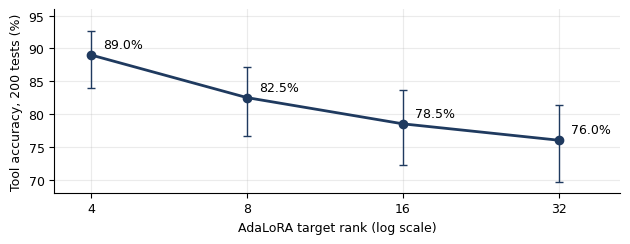

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 2.55))
y = 100 * ranks.tool
ax.errorbar(ranks["rank"], y, yerr=[y - 100 * ranks.tool_lo, 100 * ranks.tool_hi - y], color="#1F3A5F", marker="o", markersize=6, linewidth=2, capsize=3, elinewidth=1)
for x, v in zip(ranks["rank"], y):
    ax.annotate(f"{v:.1f}%", (x, v), textcoords="offset points", xytext=(9, 5), fontsize=9)
ax.set_xscale("log", base=2)
ax.set_xticks(ranks["rank"], [str(r) for r in ranks["rank"]])
ax.minorticks_off()
ax.set_xlim(3.4, 42)
ax.set_ylim(68, 96)
ax.set_xlabel("AdaLoRA target rank (log scale)", fontsize=9)
ax.set_ylabel("Tool accuracy, 200 tests (%)", fontsize=9)
ax.tick_params(labelsize=9)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig("q2_rank_plot.png", dpi=200)
plt.show()

## Where AdaLoRA put its rank

In [9]:
alloc = {}
for r in (4, 8, 16, 32):
    cfg = json.loads((WORK / "adapters" / f"AdaLoRA_r{r}" / "adapter_config.json").read_text())
    mods = {}
    for key, mask in cfg["rank_pattern"].items():
        mods.setdefault(key.split(".lora_")[0].split(".")[-1], []).append(sum(mask))
    alloc[r] = {m: round(sum(v) / len(v), 1) for m, v in mods.items()}
    print(f"r={r}, start {cfg['init_r']}:", alloc[r])

r=4, start 6: {'k_proj': 5.6, 'o_proj': 3.5, 'q_proj': 1.2, 'v_proj': 5.7}
r=8, start 12: {'k_proj': 11.3, 'o_proj': 6.7, 'q_proj': 2.5, 'v_proj': 11.5}
r=16, start 24: {'k_proj': 22.9, 'o_proj': 12.6, 'q_proj': 5.9, 'v_proj': 22.6}
r=32, start 48: {'k_proj': 46.7, 'o_proj': 25.3, 'q_proj': 11.1, 'v_proj': 44.9}


## Merge check on the first 50 test examples

In [10]:
merge_table = pd.DataFrame(merge)
print(merge_table.round(3).to_string(index=False))
first50 = {n: sum(tool[n][:50]) / 50 for n in NAMES}
print("Tool accuracy on the same 50, from the saved outputs:", first50)

  run            state  tokens_per_second  peak_memory_gb  tool_accuracy  same_output_as_unmerged
 LoRA adapter attached             60.912           3.159           0.66                      NaN
 LoRA           merged             94.938           3.151           0.66                     1.00
QLoRA adapter attached             44.338           1.356           0.64                      NaN
QLoRA           merged             61.850           1.348           0.84                     0.34
 DoRA adapter attached             35.384           3.161           0.66                      NaN
 DoRA           merged             94.380           3.153           0.66                     1.00
Tool accuracy on the same 50, from the saved outputs: {'Baseline': 0.98, 'LoRA_r8': 0.66, 'QLoRA_r8': 0.64, 'DoRA_r8': 0.66, 'AdaLoRA_r4': 0.92, 'AdaLoRA_r8': 0.84, 'AdaLoRA_r16': 0.82, 'AdaLoRA_r32': 0.74}


## Company scenario

In [11]:
rows = []
for n in NAMES:
    s = stats[n]
    wrong = [(r["user"], first_json(r["output"]).get("name") if first_json(r["output"]) else None) for r in preds[n]["company"]
             if r["gold"] and (not first_json(r["output"]) or first_json(r["output"]).get("name") != r["gold"])]
    rows.append({"run": n, "right_of_40": round(s["company_tool_accuracy"] * 40), "id_right_of_29": round(s["company_identifier_accuracy"] * 29),
                 "unauthorized_refunds": s["unauthorized_refunds"], "unnecessary_calls": s["unnecessary_calls"]})
    if n in ("Baseline", "QLoRA_r8", "AdaLoRA_r4"):
        print(n, wrong)
company = pd.DataFrame(rows)
print(company.to_string(index=False))

Baseline [('Where is my order? I placed it last Tuesday.', 'track_shipment'), ('I just want to know if ORD-8815 is on its way or still being packed.', 'track_shipment')]
QLoRA_r8 [('Kisi insaan se baat karwa dein please.', None)]
AdaLoRA_r4 [('Where is my order? I placed it last Tuesday.', 'track_shipment'), ('Mera order ORD-2290 kab tak aayega?', None), ('I just want to know if ORD-8815 is on its way or still being packed.', 'track_shipment'), ('Kisi insaan se baat karwa dein please.', None)]
        run  right_of_40  id_right_of_29  unauthorized_refunds  unnecessary_calls
   Baseline           38              28                     0                  0
    LoRA_r8           34              27                     0                  0
   QLoRA_r8           39              29                     0                  0
    DoRA_r8           34              27                     0                  0
 AdaLoRA_r4           36              27                     0                  0
 AdaLoRA_

## Failures of the best model, AdaLoRA r = 4
The Colab notebook wrote failures for r = 8, the rank used in Section 2. Section 3 then found r = 4 better, so the report uses its failures.

In [12]:
best = preds["AdaLoRA_r4"]["test"]
failures = pd.DataFrame([{"index": i, **r} for i, r in enumerate(best) if r["error"]])
failures.to_csv("best_model_r4_failures.csv", index=False, encoding="utf-8")
print(len(failures), "failures:", Counter(failures.error).most_common())
print("Failures that open conversationally:", sum(bool(OPENER.match(o)) for o in failures.output))
CHOSEN = [21, 18, 92, 15, 125]
for i in CHOSEN:
    r = best[i]
    print(f"\n[{i}] {r['error']}\nU: {r['user']}\nG: {r['gold']}\nO: {r['output']}")

61 failures: [('refused_to_call', 21), ('extra_text_around_json', 20), ('wrong_argument_value', 14), ('missing_argument', 3), ('extra_argument', 2), ('made_up_function', 1)]
Failures that open conversationally: 43

[21] refused_to_call
U: Hi, I need help with calculating my mortgage payment. I have a loan amount of $200,000, an annual interest rate of 3.5%, and a loan term of 30 years.
G: {"name": "calculate_mortgage_payment", "arguments": {"loan_amount": 200000, "interest_rate": 3.5, "loan_term": 30}}
O: Sure, I can help with that. Let me calculate it for you.

[18] extra_text_around_json
U: Hi, I need to convert 500 USD to EUR. Can you help me with that?
G: {"name": "convert_currency", "arguments": {"amount": 500, "from": "USD", "to": "EUR"}}
O: Sure, I can help with that. Here's the conversion:

```json
{
  "name": "convert_currency",
  "arguments": {
    "amount": 500,
    "from": "USD",
    "to": "EUR"
  }
}
```

[92] made_up_function
U: I need to create an invoice for a customer 

In [13]:
Path("q2_analysis.json").write_text(json.dumps({
    "qlora_percent": qlora_percent, "no_call_train": len(no_call_train), "stalls": len(stalls), "inline": len(inline),
    "refusals": refusals.to_dict("records"), "no_call_review": no_call_review.to_dict("records"), "same": same,
    "ranks": ranks.to_dict("records"), "tests": {k: list(v) for k, v in tests.items()}, "alloc": {str(k): v for k, v in alloc.items()},
    "first50": first50, "company": company.to_dict("records"), "chosen": [{"index": i, **best[i]} for i in CHOSEN],
    "failure_counts": Counter(failures.error).most_common(), "failures_conversational": sum(bool(OPENER.match(o)) for o in failures.output),
}, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("saved")

saved
